In [1]:
#import libraries 
import os
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )


<Axes: xlabel='job_title_short'>

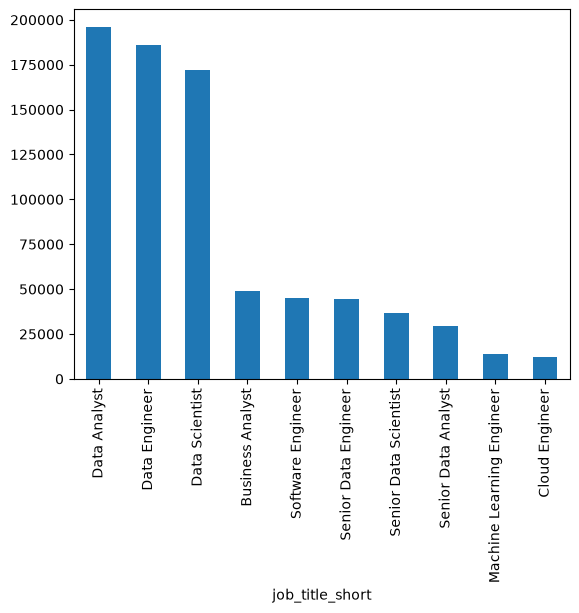

In [7]:
fig,ax=plt.subplots()

df['job_title_short'].value_counts().plot(kind="bar",ax=ax)

In [ ]:
df['job_schedule_type'].value_counts().head(3).plot(kind='bar')

job_schedule_type
Full-time     701727
Contractor     34793
Internship      8742
Name: count, dtype: int64

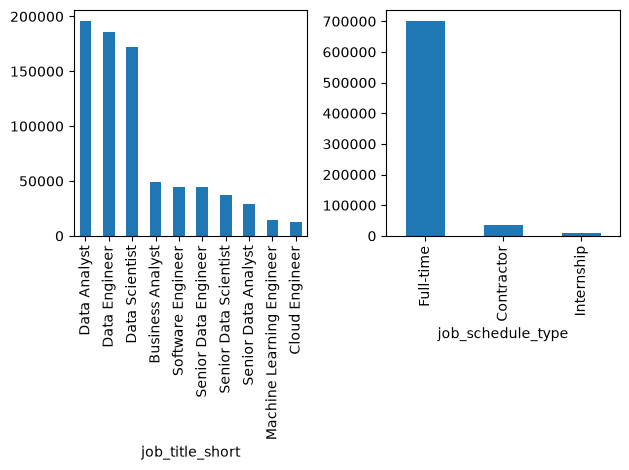

In [10]:
fig,ax=plt.subplots(1,2)
df['job_title_short'].value_counts().plot(kind="bar",ax=ax[0])
df['job_schedule_type'].value_counts().head(3).plot(kind='bar',ax=ax[1]) 

fig.tight_layout()


In [11]:
df_skills=df.copy()
df_skills=df_skills.explode('job_skills')
skills_count=df_skills.groupby(['job_skills','job_title_short']).size()
df_skills_count=skills_count.reset_index(name='skill_count')
df_skills_count.sort_values(by='skill_count',ascending=False,inplace=True)

df_skills_count

,job_skills,job_title_short,skill_count
1480,python,Data Scientist,113711
1822,sql,Data Engineer,113130
1479,python,Data Engineer,108022
1821,sql,Data Analyst,92428
1823,sql,Data Scientist,78982
...,...,...,...
2173,webex,Senior Data Scientist,1
293,codecommit,Business Analyst,1
2233,xamarin,Machine Learning Engineer,1
1087,mlr,Machine Learning Engineer,1


In [13]:
job_titles=['Data Scientist','Data Engineer','Data Analyst']

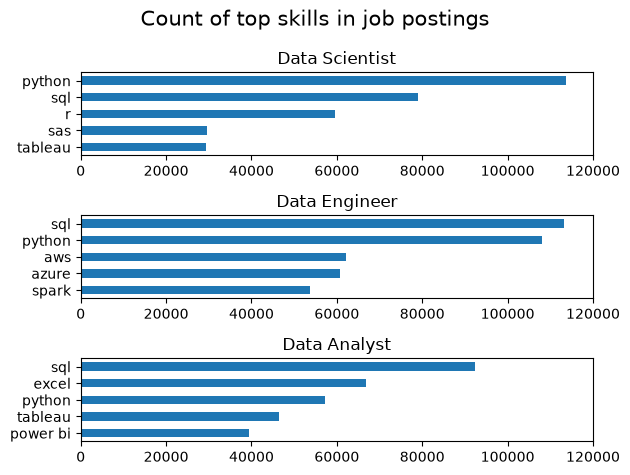

In [28]:
fig,ax=plt.subplots(3,1)

for i,job_title in enumerate(job_titles):
    df_plot=df_skills_count[df_skills_count['job_title_short']==job_title].head(5)
    df_plot.plot(kind='barh',x='job_skills',y='skill_count',ax=ax[i],title=job_title)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_xlim(0,120000)


fig.suptitle('Count of top skills in job postings',fontsize=15)
fig.tight_layout()